# 1. Données et features

On télécharge le S&P 500 (`^GSPC`) et le VIX (`^VIX`) depuis 2000, puis on construit les features quotidiennes :

| Feature | Définition |
|---|---|
| `ret` | log-rendement journalier |
| `vol_21` | volatilité réalisée sur 21 jours, annualisée |
| `mom_63` | log-rendement cumulé sur 63 jours (un trimestre) |
| `drawdown` | écart au plus haut historique |
| `vix` | niveau du VIX (volatilité implicite à 30 jours) |

Chaque valeur du jour *t* n'utilise que des données connues à la clôture de *t*.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Remonte jusqu'au dossier qui contient src/, quel que soit l'endroit d'où on lance
root = Path.cwd()
while not (root / "src").is_dir() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))
DATA = root / "data"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import download_prices
from src.features import build_features

## 1.1 Téléchargement

Le premier lancement télécharge les données et les met en cache dans `data/raw/`. Mets `REFRESH = True` pour les mettre à jour.

In [3]:
REFRESH = False

spx = download_prices("^GSPC", refresh=REFRESH)
vix = download_prices("^VIX", refresh=REFRESH)

print(len(spx), "jours de S&P 500 |", len(vix), "jours de VIX")
print(spx.index[0].date(), "→", spx.index[-1].date())

6760 jours de S&P 500 | 6762 jours de VIX
2000-01-03 → 2026-11-17


## 1.2 Features

In [4]:
df = build_features(spx, vix)

print(df.shape)
print(df.isna().sum().to_dict())
df.describe().round(4)

(6697, 5)
{'ret': 0, 'vol_21': 0, 'mom_63': 0, 'drawdown': 0, 'vix': 0}


,ret,vol_21,mom_63,drawdown,vix
count,6697.0000,6697.0000,6697.0000,6697.0000,6697.0000
mean,0.0002,0.1621,0.0159,-0.1275,19.7560
std,0.0121,0.1048,0.0783,0.1285,8.2875
min,-0.1277,0.0347,-0.5408,-0.5678,9.1400
25%,-0.0047,0.0985,-0.0199,-0.2138,14.0600
50%,0.0006,0.1352,0.0302,-0.0843,17.6700
75%,0.0058,0.1943,0.0634,-0.0142,23.0100
max,0.1096,0.9756,0.3318,0.0000,82.6900


In [5]:
DATA.mkdir(exist_ok=True)
df.to_parquet(DATA / "features.parquet")

## 1.3 Visualisation

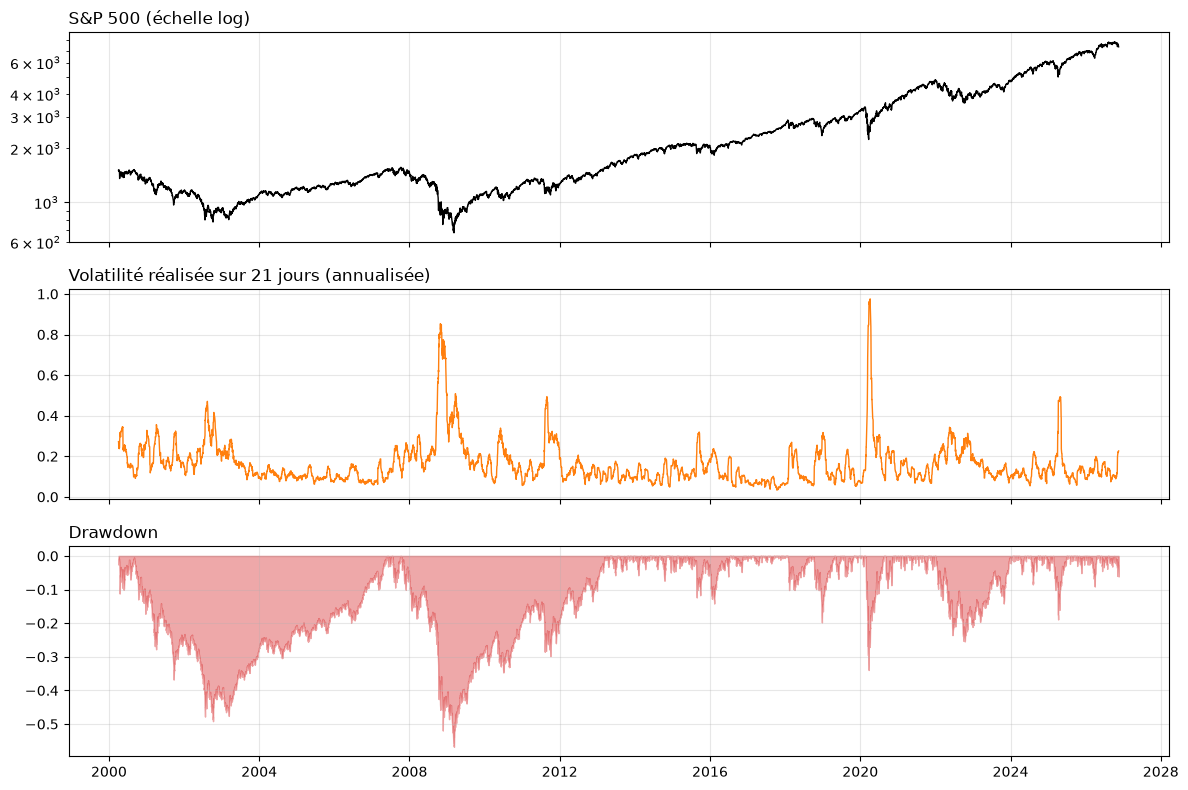

In [6]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(12, 8))

axes[0].plot(df.index, spx.loc[df.index], color="black", linewidth=1)
axes[0].set_yscale("log")
axes[0].set_title("S&P 500 (échelle log)", loc="left")

axes[1].plot(df.index, df["vol_21"], color="tab:orange", linewidth=1)
axes[1].set_title("Volatilité réalisée sur 21 jours (annualisée)", loc="left")

axes[2].fill_between(df.index, df["drawdown"], 0, color="tab:red", alpha=0.4)
axes[2].set_title("Drawdown", loc="left")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Points de contrôle

- `vol_21` autour de 0,10 à 0,20 en période calme, au-dessus de 0,80 fin 2008 et en mars 2020.
- `drawdown` vers −0,55 début 2009 et −0,34 en mars 2020.
- `ret` : moyenne proche de 0,0003, écart-type proche de 0,012.

## Ce que montre le graphique

| Période | Événement | Ce qu'on voit |
|---|---|---|
| 2000–2002 | Bulle internet | drawdown d'environ −49 %, lent et prolongé |
| 2008–2009 | Crise financière | volatilité vers 0,85, drawdown d'environ −57 % |
| 2011 | Dette européenne | pic de volatilité vers 0,5 |
| Mars 2020 | Covid | volatilité record, drawdown de −34 % en quelques semaines |
| 2022 | Hausse des taux | drawdown d'environ −25 %, volatilité modérée |
| Avril 2025 | Droits de douane | pic de volatilité vers 0,5 |

Trois faits qui motivent le projet :

1. **La volatilité arrive par grappes** : des pics brutaux, une décrue lente, des périodes calmes qui durent des années. C'est exactement ce qu'un modèle à régimes cherche à capturer.
2. **Les crises n'ont pas toutes la même forme** : 2020 est un choc violent et bref, 2002 et 2022 sont des baisses lentes à volatilité moyenne.
3. **L'asymétrie** : le marché descend vite et remonte lentement.